In [1]:
pip install notebook scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, torch, torchvision
print(sys.executable)          # should contain envs\drishti
print(torch.__version__, torchvision.__version__)
print(os.getcwd())             # should end with DRISTI
print(os.listdir("."))         # predict.py, model.pt, check_submission.py, demo folders

C:\Users\BITHIKA\anaconda3\envs\drishti\python.exe
2.11.0+cpu 0.26.0+cpu
C:\Users\BITHIKA\DRISTI
['.ipynb_checkpoints', 'accuracy_curves.png', 'check_submission.py', 'confusion_matrix.png', 'demo_keras.ipynb', 'demo_pytorch.ipynb', 'demo_test1_true_label.csv', 'demo_test2_true_label.csv', 'demo_test_1', 'demo_test_2', 'getlost.ipynb', 'leaffinders_prediction_test1.csv', 'leaffinders_prediction_test2.csv', 'LEAF_FINDERS.ipynb', 'leaf_model.pth', 'loss_curves.png', 'model.pt', 'predict.py', 'resnet18_best.pt', 'supriyo test.ipynb', 'test.ipynb', 'test_model.ipynb', 'Train', 'Untitled.ipynb', 'Untitled1.ipynb']


In [3]:
import subprocess, sys
TEAM = "LLMCurators"

for folder, tag in [("demo_test_1", "test1"), ("demo_test_2", "test2")]:
    print(subprocess.run([sys.executable, "predict.py", folder, TEAM, tag],
                         capture_output=True, text=True))
    csv = f"{TEAM}_prediction_{tag}.csv"
    r = subprocess.run([sys.executable, "check_submission.py", csv, folder, "--model", "model.pt"],
                       capture_output=True, text=True)
    print(r.stdout, r.stderr)

CompletedProcess(args=['C:\\Users\\BITHIKA\\anaconda3\\envs\\drishti\\python.exe', 'predict.py', 'demo_test_1', 'LLMCurators', 'test1'], returncode=0, stdout='Wrote LLMCurators_prediction_test1.csv with 10 rows\n', stderr='')
file    : LLMCurators_prediction_test1.csv
team    : LLMCurators
test set: test1
columns : ['file', 'predicted']
rows    : 10
images in folder: 10
every test image has exactly one prediction

prediction counts:
predicted
sp-01    2
sp-02    2
sp-03    2
sp-04    2
sp-05    2

READY - this file is valid.
 
CompletedProcess(args=['C:\\Users\\BITHIKA\\anaconda3\\envs\\drishti\\python.exe', 'predict.py', 'demo_test_2', 'LLMCurators', 'test2'], returncode=0, stdout='Wrote LLMCurators_prediction_test2.csv with 10 rows\n', stderr='')
file    : LLMCurators_prediction_test2.csv
team    : LLMCurators
test set: test2
columns : ['file', 'predicted']
rows    : 10
images in folder: 10
every test image has exactly one prediction

prediction counts:
predicted
sp-01    2
sp-02    

demo_test_1: matched 10/10  acc=1.000  macroF1=1.000


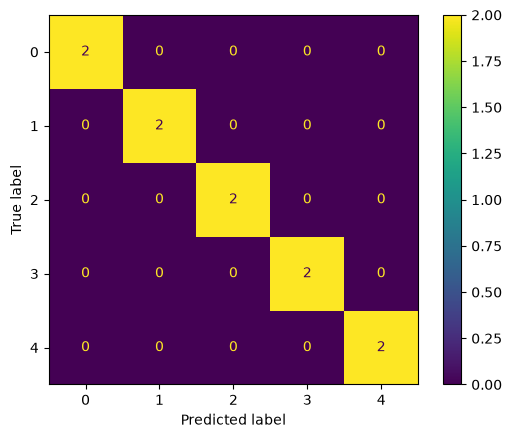

demo_test_2: matched 10/10  acc=1.000  macroF1=1.000


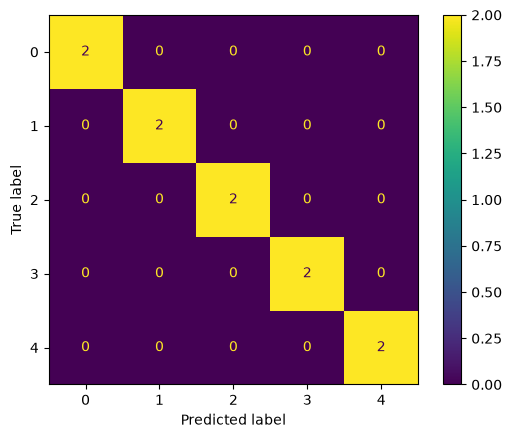

In [4]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for n in (1, 2):
    p = pd.read_csv(f"{TEAM}_prediction_test{n}.csv"); p.columns = ["f", "pred"]
    t = pd.read_csv(f"demo_test{n}_true_label.csv");   t.columns = ["f", "true"]
    m = p.merge(t, on="f")
    print(f"demo_test_{n}: matched {len(m)}/{len(p)}  acc={accuracy_score(m.true, m.pred):.3f}  "
          f"macroF1={f1_score(m.true, m.pred, average='macro'):.3f}")
    ConfusionMatrixDisplay(confusion_matrix(m.true, m.pred)).plot()
    plt.show()

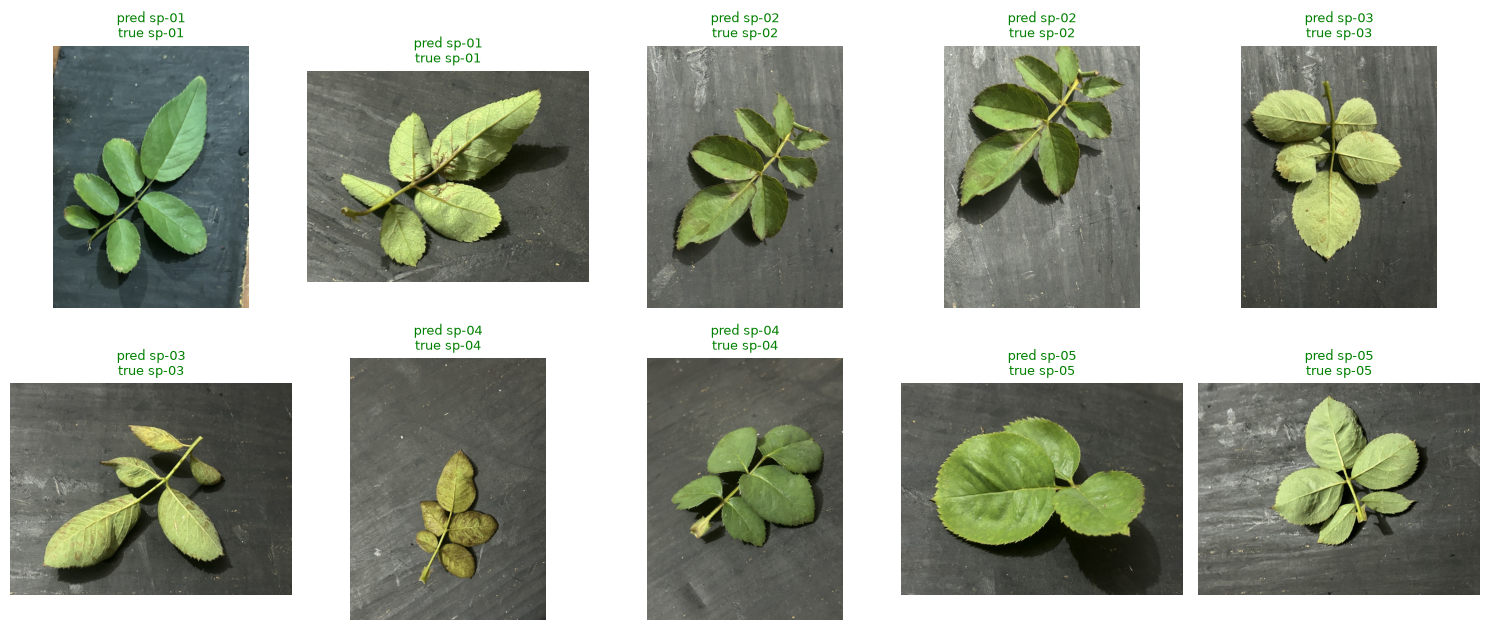

In [5]:
import os, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

n, folder = 1, "demo_test_1"          # change to 2 and "demo_test_2" for the second set
p = pd.read_csv(f"{TEAM}_prediction_test{n}.csv"); p.columns = ["f", "pred"]
t = pd.read_csv(f"demo_test{n}_true_label.csv");   t.columns = ["f", "true"]
m = p.merge(t, on="f")

cols = 5
rows = (len(m) + cols - 1) // cols
plt.figure(figsize=(3 * cols, 3.2 * rows))
for i, r in enumerate(m.itertuples()):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(Image.open(os.path.join(folder, r.f)).convert("RGB"))
    ok = r.pred == r.true
    plt.title(f"pred {r.pred}\ntrue {r.true}", color="green" if ok else "red", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()